# Métricas de flujo del fulfilment (P1, P2, M2)
Responsable: Persona 3 · Entrega 1 · Requiere `uv run novaretail all` antes de ejecutar.

In [1]:
import sys
from pathlib import Path
for p in [Path.cwd() / "src", Path.cwd().parent / "src"]:
    if p.exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))

import pandas as pd
import matplotlib.pyplot as plt
from novaretail import flow
from novaretail.config import CLEAN, DATA_END, FIGURES

FIGURES.mkdir(parents=True, exist_ok=True)
events = pd.read_parquet(CLEAN / "fulfilment_events.parquet")
orders = pd.read_parquet(CLEAN / "orders.parquet")

## 1. Tiempos por etapa, P50 y P90 por almacén y transportista

,warehouse,n_orders,created_to_picked_p50,created_to_picked_p90,picked_to_packed_p50,picked_to_packed_p90,packed_to_shipped_p50,packed_to_shipped_p90,shipped_to_delivered_p50,shipped_to_delivered_p90,total_hours_p50,total_hours_p90
0,WH-BCN,12577,7.09,12.96,8.05,18.97,4.94,27.49,23.73,62.82,59.40,92.96
1,WH-BIO,8119,5.04,11.76,1.13,2.99,4.43,28.94,39.63,71.18,58.87,92.95
2,WH-MAD,13873,4.98,11.70,1.11,2.89,4.42,28.89,23.88,49.30,46.57,74.34
3,WH-SVQ,10361,5.01,11.70,1.10,2.95,4.40,28.63,25.02,50.46,47.41,78.45


,carrier,n_orders,created_to_picked_p50,created_to_picked_p90,picked_to_packed_p50,picked_to_packed_p90,packed_to_shipped_p50,packed_to_shipped_p90,shipped_to_delivered_p50,shipped_to_delivered_p90,total_hours_p50,total_hours_p90
0,EnviaYa,12970,5.47,12.03,1.41,10.16,4.57,28.47,26.60,48.40,49.52,77.41
1,PaqPlus,8230,5.53,12.09,1.35,9.80,4.60,28.67,38.45,69.33,59.19,90.39
2,RapidLog,12933,5.55,11.97,1.54,10.96,4.62,28.67,21.71,46.43,44.03,69.22
3,TransIberia,10797,5.58,12.28,1.71,11.55,4.67,28.64,39.83,93.50,61.81,116.18


,month,n_orders,created_to_picked_p50,created_to_picked_p90,picked_to_packed_p50,picked_to_packed_p90,packed_to_shipped_p50,packed_to_shipped_p90,shipped_to_delivered_p50,shipped_to_delivered_p90,total_hours_p50,total_hours_p90
0,2025-01,2072,5.28,11.70,1.44,9.81,4.72,28.40,26.23,66.62,50.68,88.54
1,2025-02,1357,4.87,11.52,1.37,9.46,4.58,29.26,24.52,55.43,48.98,84.56
2,2025-03,1614,4.99,11.62,1.44,9.90,4.86,29.66,24.77,56.27,50.28,86.95
3,2025-04,1702,5.23,11.91,1.40,9.53,4.44,27.77,25.27,62.88,48.00,82.97
4,2025-05,1708,4.86,11.47,1.41,9.41,4.59,29.06,25.48,57.27,51.13,82.82
5,2025-06,1793,5.08,11.87,1.40,9.98,4.58,28.82,24.87,64.28,48.93,86.50
6,2025-07,2012,5.09,11.89,1.41,9.97,4.52,27.30,24.90,65.64,47.79,86.01
7,2025-08,1569,4.54,11.61,1.42,9.72,4.75,29.12,25.96,66.20,51.33,86.69
8,2025-09,1848,5.70,12.17,1.40,10.51,4.53,28.30,25.37,63.39,50.60,86.66
9,2025-10,1982,5.70,12.08,1.45,10.23,4.60,28.63,25.93,63.70,50.45,86.56


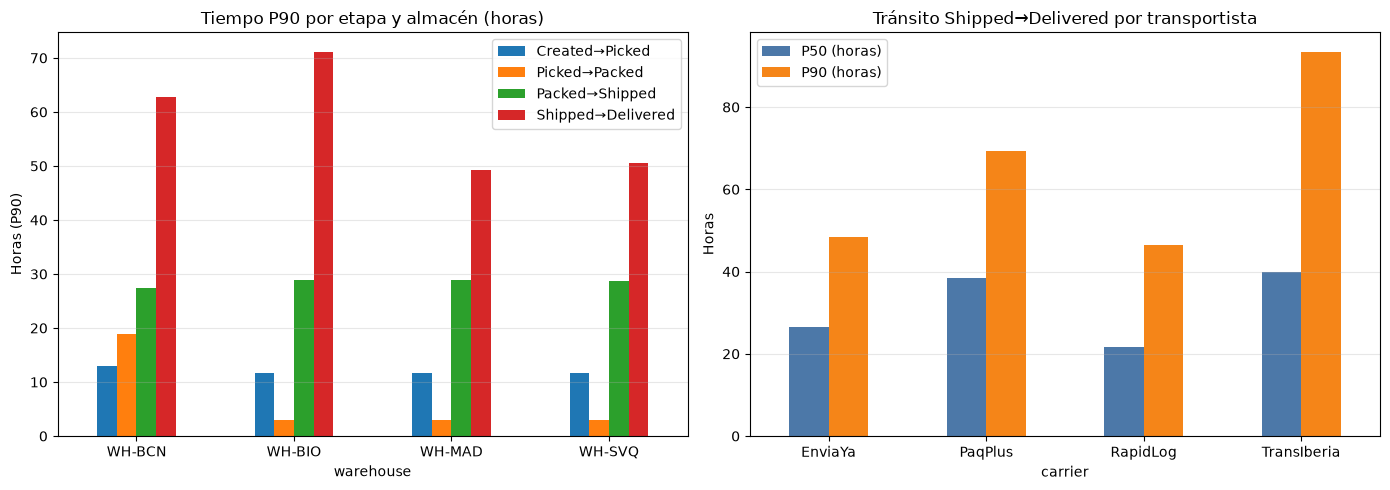

In [2]:
durations = flow.stage_durations(events)
p_wh = flow.percentiles(durations, by=["warehouse"])
p_carrier = flow.percentiles(durations, by=["carrier"])
p_month = flow.percentiles(durations, by=["month"])

display(p_wh)
display(p_carrier)
display(p_month)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
p90_cols = ["created_to_picked_p90", "picked_to_packed_p90", "packed_to_shipped_p90", "shipped_to_delivered_p90"]
labels = ["Created→Picked", "Picked→Packed", "Packed→Shipped", "Shipped→Delivered"]

p_wh_plot = p_wh.set_index("warehouse")[p90_cols]
p_wh_plot.columns = labels
p_wh_plot.plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Tiempo P90 por etapa y almacén (horas)")
axes[0].set_ylabel("Horas (P90)")
axes[0].grid(axis="y", alpha=0.3)

p_car_plot = p_carrier.set_index("carrier")[["shipped_to_delivered_p50", "shipped_to_delivered_p90"]]
p_car_plot.columns = ["P50 (horas)", "P90 (horas)"]
p_car_plot.plot(kind="bar", ax=axes[1], rot=0, color=["#4C78A8", "#F58518"])
axes[1].set_title("Tránsito Shipped→Delivered por transportista")
axes[1].set_ylabel("Horas")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES / "flujo_p50_p90_etapas.png", dpi=200, bbox_inches="tight")
plt.show()

## 2. WIP diario y cuello de botella

WIP medio diario: 719.1 | WIP máximo: 1400


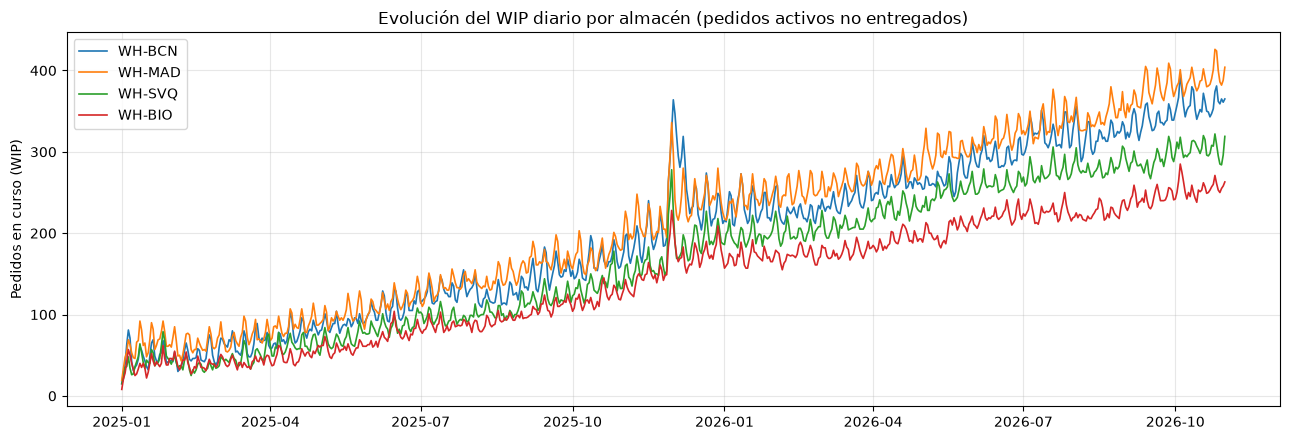

In [3]:
wip = flow.daily_wip(events)
print("WIP medio diario:", round(wip["wip_total"].mean(), 1), "| WIP máximo:", int(wip["wip_total"].max()))

fig, ax = plt.subplots(figsize=(13, 4.5))
for wh in ["WH-BCN", "WH-MAD", "WH-SVQ", "WH-BIO"]:
    if wh in wip.columns:
        ax.plot(wip["date"], wip[wh], label=wh, linewidth=1.2)
ax.set_title("Evolución del WIP diario por almacén (pedidos activos no entregados)")
ax.set_ylabel("Pedidos en curso (WIP)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES / "flujo_wip_diario.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Recomendación operativa: pedidos que requieren intervención hoy

In [4]:
action_orders = flow.orders_needing_action(events, orders, today=pd.Timestamp(DATA_END))
print(f"Total pedidos a intervenir hoy: {len(action_orders)}")
display(action_orders.groupby(["warehouse", "current_stage", "risk_level"]).size().unstack(fill_value=0))
display(action_orders.head(15))

Total pedidos a intervenir hoy: 12


,risk_level,Riesgo alto,Vencido
warehouse,current_stage,,
WH-BCN,shipped,0,3
WH-BIO,shipped,3,2
WH-MAD,shipped,1,0
WH-SVQ,shipped,2,1


,order_id,channel,warehouse,carrier,current_stage,created_ts,promised_ts,hours_to_promise,risk_level,recommended_action
0,NR0077781,web,WH-BCN,TransIberia,shipped,2026-10-25 07:16:01,2026-10-28 07:16:01,-88.7,Vencido,Escalar incidencia con transportista TransIber...
1,NR0077889,app,WH-BIO,PaqPlus,shipped,2026-10-26 05:35:34,2026-10-29 05:35:34,-66.4,Vencido,Escalar incidencia con transportista PaqPlus y...
2,NR0078084,marketplace,WH-BCN,TransIberia,shipped,2026-10-27 18:52:22,2026-10-31 18:52:22,-5.1,Vencido,Escalar incidencia con transportista TransIber...
3,NR0078216,app,WH-SVQ,TransIberia,shipped,2026-10-28 20:53:18,2026-10-31 20:53:18,-3.1,Vencido,Escalar incidencia con transportista TransIber...
4,NR0078220,app,WH-BIO,PaqPlus,shipped,2026-10-28 21:30:49,2026-10-31 21:30:49,-2.5,Vencido,Escalar incidencia con transportista PaqPlus y...
5,NR0078224,app,WH-BCN,TransIberia,shipped,2026-10-28 21:48:24,2026-10-31 21:48:24,-2.2,Vencido,Escalar incidencia con transportista TransIber...
6,NR0078244,app,WH-SVQ,TransIberia,shipped,2026-10-29 09:49:25,2026-11-01 09:49:25,9.8,Riesgo alto,Escalar incidencia con transportista TransIber...
7,NR0078256,web,WH-MAD,TransIberia,shipped,2026-10-29 11:41:43,2026-11-01 11:41:43,11.7,Riesgo alto,Escalar incidencia con transportista TransIber...
8,NR0078277,web,WH-BIO,PaqPlus,shipped,2026-10-29 16:04:59,2026-11-01 16:04:59,16.1,Riesgo alto,Escalar incidencia con transportista PaqPlus y...
9,NR0078279,web,WH-SVQ,TransIberia,shipped,2026-10-29 16:16:42,2026-11-01 16:16:42,16.3,Riesgo alto,Escalar incidencia con transportista TransIber...
